# Bab 10 – Clustering Techniques

## Ringkasan Bab
**Clustering** adalah pembelajaran *unsupervised*: mengelompokkan data berdasarkan kemiripan tanpa label. Bab ini membahas
**K-Means**, **hierarchical clustering**, **DBSCAN** (berbasis kepadatan), metrik evaluasi cluster, cara memilih algoritma,
teknik lanjutan (seperti Gaussian Mixture), dan latihan pada data berdimensi tinggi.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_blobs, make_moons, load_digits
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, MiniBatchKMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
import warnings; warnings.filterwarnings("ignore")

## 1. Pengantar Clustering
Tujuannya: data dalam satu cluster sebisa mungkin mirip, dan antar cluster sebisa mungkin berbeda. Karena tidak ada label,
hasilnya bergantung pada algoritma, ukuran jarak, dan scaling. Aplikasi: segmentasi pelanggan, kompresi gambar, deteksi anomali.

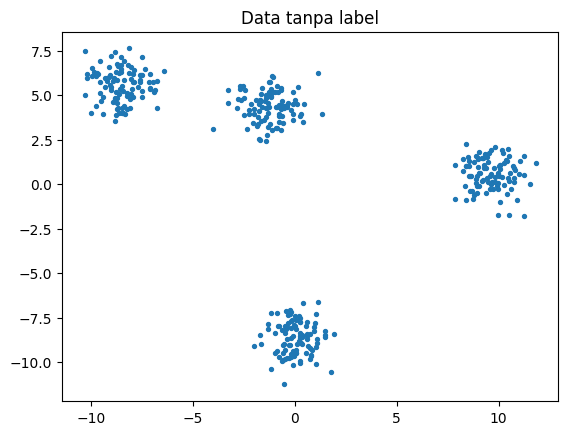

In [2]:
Xb, yb = make_blobs(n_samples=400, centers=4, cluster_std=.9, random_state=7)
plt.scatter(Xb[:, 0], Xb[:, 1], s=8); plt.title("Data tanpa label"); plt.show()

## 2. K-Means
Algoritma (Lloyd): (1) pilih K pusat awal; (2) tetapkan tiap titik ke pusat terdekat; (3) hitung ulang pusat sebagai rata-rata anggota;
(4) ulangi sampai konvergen. Fungsi tujuannya meminimalkan **inertia** (jumlah kuadrat jarak ke pusat).
Kelemahan: harus menentukan K, peka terhadap inisialisasi (sklearn memakai `k-means++`), dan hanya cocok untuk cluster berbentuk bulat.
Metode memilih K: **elbow** (inertia) dan **silhouette**.

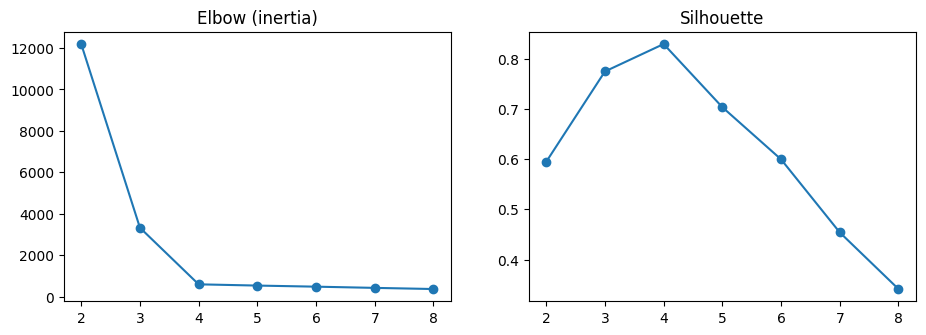

K terbaik menurut silhouette: 4


In [3]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(Xb); inertia.append(km.inertia_); sil.append(silhouette_score(Xb, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette")
plt.show(); print("K terbaik menurut silhouette:", list(ks)[int(np.argmax(sil))])

## 3. Hierarchical Clustering
Pendekatan **agglomerative**: mulai dari tiap titik sebagai cluster, lalu terus menggabungkan dua cluster terdekat. Hasilnya berupa pohon
**dendrogram** yang bisa dipotong pada tinggi tertentu. Pilihan `linkage`: `ward` (meminimalkan kenaikan varians; paling umum),
`complete`, `average`, `single` (rawan efek rantai).

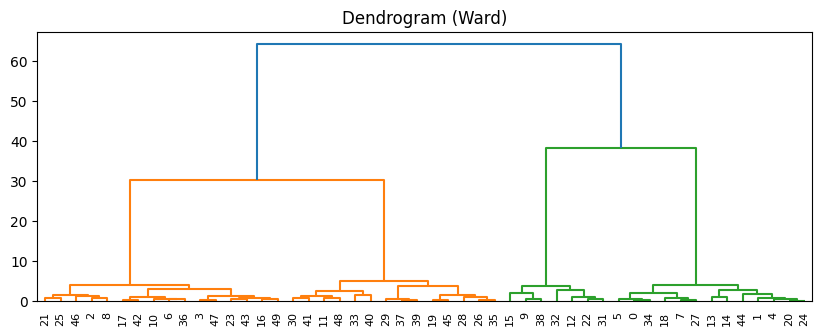

ARI terhadap label asli: 1.0


In [4]:
sub = Xb[::8]
plt.figure(figsize=(10, 3.5)); dendrogram(linkage(sub, "ward")); plt.title("Dendrogram (Ward)"); plt.show()
agg = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(Xb)
print("ARI terhadap label asli:", round(adjusted_rand_score(yb, agg.labels_), 3))

## 4. Density-Based Clustering dengan DBSCAN
DBSCAN mengelompokkan titik yang berdekatan secara padat. Dua parameter: **eps** (radius tetangga) dan **min_samples**.
Jenis titik: *core* (punya ≥ min_samples tetangga dalam eps), *border*, dan *noise* (label −1).
Keunggulan: tidak perlu K, mampu menemukan cluster berbentuk bebas, dan menandai outlier. Kelemahan: sulit bila kepadatan antar cluster berbeda.
Tips memilih eps: grafik jarak ke tetangga ke-k yang diurutkan, lalu cari "siku"-nya.

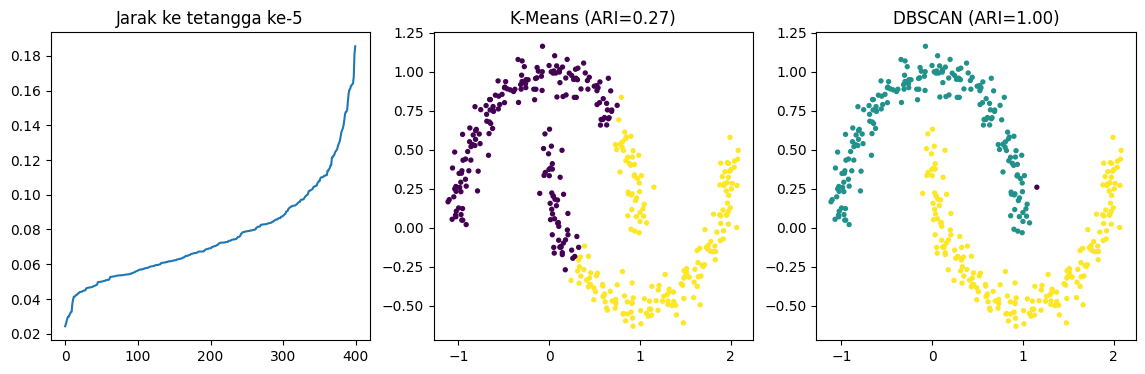

In [5]:
Xm, ym = make_moons(400, noise=.07, random_state=0)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
d = np.sort(NearestNeighbors(n_neighbors=5).fit(Xm).kneighbors(Xm)[0][:, -1]); ax[0].plot(d); ax[0].set_title("Jarak ke tetangga ke-5")
for a, (n, m) in zip(ax[1:], [("K-Means", KMeans(2, n_init=10, random_state=0)), ("DBSCAN", DBSCAN(eps=.15, min_samples=5))]):
    lab = m.fit_predict(Xm); a.scatter(Xm[:, 0], Xm[:, 1], c=lab, s=8, cmap="viridis"); a.set_title(f"{n} (ARI={adjusted_rand_score(ym, lab):.2f})")
plt.show()

## 5. Metrik Evaluasi Cluster
**Internal (tanpa label):**
* **Silhouette** ∈ [−1, 1]: makin tinggi makin baik (cohesion vs separation).
* **Davies-Bouldin**: makin **rendah** makin baik.
* **Calinski-Harabasz**: makin **tinggi** makin baik.

**Eksternal (ada label pembanding):** **Adjusted Rand Index (ARI)** dan Normalized Mutual Information (NMI).
Metrik internal cenderung menyukai cluster bulat, jadi kurang adil untuk DBSCAN pada bentuk non-konveks.

In [6]:
Xi = StandardScaler().fit_transform(load_iris().data); yi = load_iris().target
rows = []
for n, m in [("K-Means", KMeans(3, n_init=10, random_state=0)), ("Agglomerative", AgglomerativeClustering(3)), ("GMM", GaussianMixture(3, random_state=0))]:
    lab = m.fit_predict(Xi)
    rows.append({"algoritma": n, "silhouette": silhouette_score(Xi, lab), "davies-bouldin": davies_bouldin_score(Xi, lab),
                 "calinski-harabasz": calinski_harabasz_score(Xi, lab), "ARI": adjusted_rand_score(yi, lab)})
pd.DataFrame(rows).round(3)

,algoritma,silhouette,davies-bouldin,calinski-harabasz,ARI
0,K-Means,0.460,0.834,241.904,0.620
1,Agglomerative,0.447,0.803,222.719,0.615
2,GMM,0.374,1.081,187.774,0.904


## 6. Memilih Algoritma Clustering yang Tepat
| Algoritma | Cocok bila | Perlu K? | Menangani noise? |
|---|---|---|---|
| K-Means | cluster bulat, ukuran mirip, data besar | ya | tidak |
| Hierarchical | ingin melihat struktur bertingkat, data kecil | tidak (potong dendrogram) | kurang |
| DBSCAN | bentuk bebas, ada outlier | tidak | ya |
| Gaussian Mixture | cluster elips, butuh keanggotaan *soft* | ya | tidak |

## 7. Teknik Clustering Lanjutan
* **Gaussian Mixture Model (GMM):** memodelkan data sebagai campuran distribusi Gaussian dan dilatih dengan algoritma EM. Memberi **probabilitas keanggotaan**, dan jumlah komponen bisa dipilih lewat BIC/AIC.
* **MiniBatchKMeans:** versi K-Means yang jauh lebih cepat untuk data besar.

In [7]:
Xg, _ = make_blobs(n_samples=500, centers=3, cluster_std=[1, 2.2, .6], random_state=3)
bic = [GaussianMixture(k, random_state=0).fit(Xg).bic(Xg) for k in range(1, 7)]
print("Jumlah komponen terbaik menurut BIC:", int(np.argmin(bic)) + 1)
gmm = GaussianMixture(3, random_state=0).fit(Xg); print("Probabilitas keanggotaan 2 titik:\n", gmm.predict_proba(Xg[:2]).round(3))
import time; Xl, _ = make_blobs(100000, centers=5, random_state=0)
for n, m in [("KMeans", KMeans(5, n_init=3, random_state=0)), ("MiniBatchKMeans", MiniBatchKMeans(5, n_init=3, random_state=0))]:
    t = time.time(); m.fit(Xl); print(f"{n:16s} inertia={m.inertia_:.0f} waktu={time.time()-t:.2f} dtk")

Jumlah komponen terbaik menurut BIC: 3
Probabilitas keanggotaan 2 titik:
 [[0.    0.999 0.001]
 [0.    0.003 0.997]]
KMeans           inertia=182907 waktu=0.08 dtk
MiniBatchKMeans  inertia=182951 waktu=0.02 dtk


## 8. Latihan Praktik

### Latihan 1 – K-Means pada Dataset Iris (dengan Elbow)

In [8]:
km = KMeans(3, n_init=10, random_state=0).fit(Xi)
print("ARI:", round(adjusted_rand_score(yi, km.labels_), 3), "| silhouette:", round(silhouette_score(Xi, km.labels_), 3))
print(pd.crosstab(yi, km.labels_, rownames=["spesies"], colnames=["cluster"]))

ARI: 0.62 | silhouette: 0.46
cluster   0   1   2
spesies            
0         0  50   0
1        39   0  11
2        14   0  36


### Latihan 2 – Membandingkan DBSCAN dan K-Means pada Data Non-Konveks
Sudah ditunjukkan pada bagian 4 (dataset *moons*). Berikut contoh pengaruh `eps`.

In [9]:
for eps in [0.05, 0.15, 0.4]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm)
    print(f"eps={eps}: cluster={len(set(lab)-{-1})}, noise={int((lab==-1).sum())}, ARI={adjusted_rand_score(ym, lab):.2f}")

eps=0.05: cluster=21, noise=273, ARI=0.01
eps=0.15: cluster=2, noise=1, ARI=1.00
eps=0.4: cluster=1, noise=0, ARI=0.00


### Latihan 3 – Clustering Data Berdimensi Tinggi dengan PCA dan t-SNE
Dataset digit (64 fitur) di-cluster, lalu divisualisasikan dalam 2-D.

ARI K-Means (setelah PCA) terhadap digit asli: 0.553


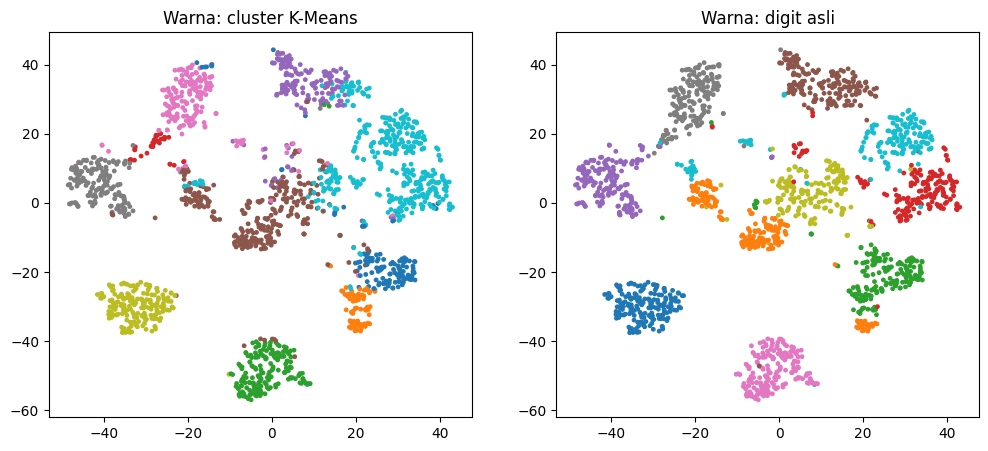

In [10]:
dg = load_digits(); Xd = StandardScaler().fit_transform(dg.data)
Xp = PCA(n_components=30, random_state=0).fit_transform(Xd)
lab = KMeans(10, n_init=10, random_state=0).fit_predict(Xp)
print("ARI K-Means (setelah PCA) terhadap digit asli:", round(adjusted_rand_score(dg.target, lab), 3))
E = TSNE(2, init="pca", random_state=0).fit_transform(Xp)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(E[:, 0], E[:, 1], c=lab, cmap="tab10", s=6); ax[0].set_title("Warna: cluster K-Means")
ax[1].scatter(E[:, 0], E[:, 1], c=dg.target, cmap="tab10", s=6); ax[1].set_title("Warna: digit asli"); plt.show()

**Kesimpulan:** tidak ada algoritma clustering yang terbaik untuk semua kasus. Lakukan scaling, visualisasikan hasilnya, dan
gabungkan beberapa metrik evaluasi dengan pengetahuan domain.